# 학습 회원 이탈 예측

온라인 학습 서비스 회원의 최근 3개월 기록으로 누가 곧 그만둘지 예측합니다.
데이터 탐색부터 모델 학습·평가·앙상블까지 이 노트북 하나로 처음부터 끝까지 실행됩니다.

| 순서 | 내용 |
|---|---|
| 0 | 시작하기: 필요한 것, 설정 |
| 1 | 데이터 둘러보기 |
| 2 | 성능 지표 AUC |
| 3 | 직전 달 학습 지표 |
| 4 | 시험 점수와 그 변화 |
| 5 | 시험을 안 보는 것이 신호다 |
| 6 | 모델 학습과 평가 |
| 7 | 정리 |

## 0. 시작하기

### 필요한 것

**Python 3.10 이상**과 아래 라이브러리가 필요합니다. GPU 는 쓰지 않습니다(CPU 만으로 충분).

| 라이브러리 | 용도 | 검증한 버전 |
|---|---|---|
| numpy | 배열 계산 | 2.3.5 |
| pandas | 표 데이터 | 3.0.3 |
| scipy | 통계 검정, 순위 계산 | 1.18.0 |
| scikit-learn | 교차검증 분할, AUC, 로지스틱 회귀, 결정나무 모음 | 1.9.0 |
| torch | 부드러운 AUC 로 학습하는 모델 (CPU) | 2.13.0 |
| matplotlib | 그림 | 3.11.0 |
| jupyterlab | 노트북 실행 | – |

같은 폴더의 `requirements.txt` 로 한 번에 설치할 수 있습니다.

```bash
python -m venv .venv
source .venv/bin/activate          # Windows: .venv\Scripts\activate
pip install -r requirements.txt
jupyter lab
```

torch 는 CPU 판이면 충분합니다. 설치가 무거우면 `pip install torch --index-url https://download.pytorch.org/whl/cpu` 로 CPU 판만 받을 수 있습니다.

### 데이터

`Study.공유.csv` 를 다음 위치에 둡니다.

```
study/
├── data/Study.공유.csv
└── notebooks/churn_report.ipynb   ← 이 노트북
```

### 실행 시간

6장의 모델 학습이 대부분을 차지합니다. Apple M4 CPU 기준으로 `QUICK = True` (5번 채점) 약 2분,
`QUICK = False` (25번 채점, 보고서 수치) 약 8분입니다. 아래 설정 칸에서 고릅니다.

In [1]:
import itertools
import os
import sys
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
import torch
from matplotlib import font_manager
from scipy.special import expit as sigmoid   # 1 / (1 + e^-z), 큰 값에서도 넘치지 않음
from scipy.stats import fisher_exact, mannwhitneyu, rankdata
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split

print("Python", sys.version.split()[0])
for m in (np, pd, scipy, sklearn, torch, matplotlib):
    print(f"{m.__name__:12s} {m.__version__}")

Python 3.12.12
numpy        2.3.5
pandas       3.0.3
scipy        1.18.0
sklearn      1.9.0
torch        2.13.0
matplotlib   3.11.0


In [2]:
# ── 설정 ─────────────────────────────────────────────────────────────
QUICK = False          # True: 5번 채점(약 2분) / False: 25번 채점(약 8분, 보고서 수치)

N_SPLITS = 5                          # 교차검증 묶음 수
N_REPEATS = 1 if QUICK else 5         # 묶음 나누기를 몇 번 반복할지
torch.set_num_threads(min(8, os.cpu_count() or 1))

# 노트북이 notebooks/ 안에 있어도, study/ 에서 열어도 데이터를 찾는다
ROOT = Path("..") if Path("../data/Study.공유.csv").exists() else Path(".")
DATA = ROOT / "data" / "Study.공유.csv"
assert DATA.exists(), f"데이터 파일이 없습니다: {DATA.resolve()}"

# 한글 글꼴: 설치된 것 중 첫 번째를 쓴다
KOREAN_FONTS = ["Apple SD Gothic Neo", "AppleGothic", "Malgun Gothic", "NanumGothic",
                "Noto Sans CJK KR", "Noto Sans KR"]
installed = {f.name for f in font_manager.fontManager.ttflist}
font = next((f for f in KOREAN_FONTS if f in installed), None)
if font is None:
    print("한글 글꼴을 찾지 못했습니다. 그림의 한글이 네모로 보이면 NanumGothic 등을 설치하세요.")
plt.rcParams.update({
    "font.family": font or "sans-serif",
    "axes.unicode_minus": False,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 110,
})
STAY, CHURN = "#2a78d6", "#eb6834"     # 잔류 파랑, 이탈 주황
pd.set_option("display.precision", 3)
print(f"데이터 {DATA.resolve()}\n글꼴 {font}\n채점 {N_SPLITS * N_REPEATS}번")

데이터 /Volumes/storage/data_proj/KANT/study/data/Study.공유.csv
글꼴 Apple SD Gothic Neo
채점 25번


## 1. 데이터 둘러보기

회원 한 명이 한 줄입니다. `survived` 가 정답이고 **0 = 이탈(그만둠), 1 = 잔류(계속 다님)** 입니다.

| 항목 | 뜻 |
|---|---|
| Month | 서비스 이용 기간 (개월) |
| AGE | 나이 |
| StudyCnt | 그 달에 공부한 횟수 |
| StudyIndex | 학력 지수 (0–100) |
| Exam1 · Exam2 · Exam3 | 세 종류 시험 점수, 안 본 달은 비어 있음 |

M1 = 직전 달, M2 = 두 달 전, M3 = 세 달 전입니다.

In [3]:
df = pd.read_csv(DATA)
ORIGINAL_COLS = list(df.columns)                    # 이후 분석용 열을 더하기 전의 원래 열
df["churn"] = (df["survived"] == 0).astype(int)     # 분석 편의상 이탈 = 1 로 뒤집은 열
print(f"회원 {len(df):,}명, 이탈 {df.churn.sum()}명 ({df.churn.mean():.2%})")
df.head()

회원 30,664명, 이탈 868명 (2.83%)


,ID,survived,Month,AGE,StudyCnt_M1,StudyCntCnt_M2,StudyCntCnt_M3,StudyIndex_M1,StudyIndex_M2,StudyIndex_M3,Exam1_M1,Exam1_M2,Exam1_M3,Exam2_M1,Exam2_M2,Exam2_M3,Exam3_M1,Exam3_M2,Exam3_M3,churn
0,1,1,39,52,19.0,14.0,20.0,45.0,41.0,57.0,92.76,96.43,93.75,84.96,85.25,92.28,67.42,76.65,95.88,0
1,2,1,5,49,31.0,22.0,27.0,72.0,73.0,81.0,96.65,95.45,95.56,105.90,109.56,111.27,102.57,94.68,105.88,0
2,3,1,1,19,2.0,NaN,NaN,41.0,NaN,NaN,100.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
3,4,1,8,17,31.0,7.0,NaN,88.0,63.0,NaN,92.14,100.00,NaN,112.28,105.98,NaN,119.20,NaN,NaN,0
4,5,1,7,17,42.0,47.0,41.0,32.0,33.0,33.0,62.78,71.20,71.90,NaN,NaN,NaN,NaN,NaN,NaN,0


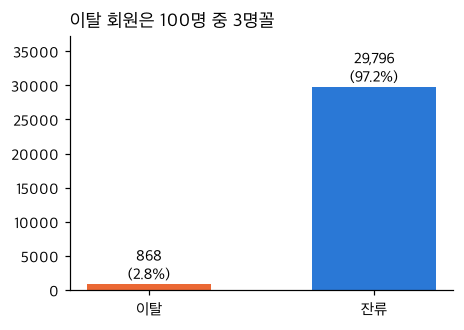

In [4]:
counts = df["churn"].map({1: "이탈", 0: "잔류"}).value_counts()[["이탈", "잔류"]]
fig, ax = plt.subplots(figsize=(4.5, 3))
ax.bar(counts.index, counts.values, color=[CHURN, STAY], width=0.55)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v / len(df):.1%})", ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.25)
ax.set_title("이탈 회원은 100명 중 3명꼴", loc="left")
plt.show()

"모두 계속 다닌다"고 찍기만 해도 97% 를 맞힙니다. 그래서 맞힌 비율(정확도)로는 모델을 평가할 수 없습니다.

## 2. 성능 지표 AUC

**AUC** 는 이탈 회원 한 명과 잔류 회원 한 명을 뽑았을 때, 모델이 이탈 회원에게 더 높은 위험 점수를 줄 확률입니다.
0.5 는 동전 던지기, 1.0 은 완벽입니다.

정의 그대로 계산해 보면 sklearn 의 `roc_auc_score` 와 같은 값이 나옵니다.
아래는 "직전 달 학력 지수가 낮을수록 위험하다"는 단순한 규칙의 AUC 입니다.

In [5]:
score = -df["StudyIndex_M1"]           # 낮을수록 위험 → 부호를 뒤집어 '위험 점수'로
ok = score.notna()
s, y_ok = score[ok].to_numpy(), df.churn[ok].to_numpy()

pos, neg = s[y_ok == 1], s[y_ok == 0]
by_pairs = ((pos[:, None] > neg[None, :]).mean()
            + 0.5 * (pos[:, None] == neg[None, :]).mean())   # 동점은 반만 인정

print(f"쌍 비교로 계산 {by_pairs:.4f}")
print(f"roc_auc_score  {roc_auc_score(y_ok, s):.4f}")

쌍 비교로 계산 0.6611
roc_auc_score  0.6611


### 부드러운 AUC

모델 학습은 "점수를 조금 바꾸면 성능이 얼마나 좋아지나"를 따라 규칙을 고쳐 나가는 과정입니다.
AUC 는 쌍마다 "맞혔다/틀렸다"로 딱 끊기는 계단 `1[s_이탈 > s_잔류]` 이라 이 방향을 알려 주지 못합니다.
계단을 부드러운 곡선 `σ((s_이탈 − s_잔류)/τ)` 로 바꾸면 미분할 수 있게 되고, 6장의 모델들은 이 값을 키우도록 학습합니다.
τ 를 줄일수록 계단에 가까워져 실제 AUC 에 다가갑니다.

In [6]:
def soft_auc_np(s_pos, s_neg, tau=1.0):
    return sigmoid((s_pos[:, None] - s_neg[None, :]) / tau).mean()

for tau in [10, 3, 1, 0.1]:
    print(f"τ = {tau:>4}: 부드러운 AUC {soft_auc_np(pos, neg, tau):.4f}")
print(f"실제 AUC      {roc_auc_score(y_ok, s):.4f}")

τ =   10: 부드러운 AUC 0.6376


τ =    3: 부드러운 AUC 0.6583


τ =    1: 부드러운 AUC 0.6608


τ =  0.1: 부드러운 AUC 0.6611
실제 AUC      0.6611


## 3. 직전 달 학습 지표

이탈 회원과 잔류 회원의 **중앙값**(줄 세웠을 때 한가운데 값)을 달별로 비교합니다.
차이가 세 달 전에는 작다가 직전 달로 갈수록 커집니다.

In [7]:
cols = {"StudyIndex": ["StudyIndex_M3", "StudyIndex_M2", "StudyIndex_M1"],
        "StudyCnt":   ["StudyCntCnt_M3", "StudyCntCnt_M2", "StudyCnt_M1"]}   # 원본 열 이름이 달마다 다르다
rows = []
for name, cs in cols.items():
    for c, m in zip(cs, ["M3", "M2", "M1"]):
        med = df.groupby("churn")[c].median()
        rows.append({"항목": name, "달": m, "이탈 중앙값": med[1], "잔류 중앙값": med[0],
                     "차이": med[0] - med[1]})
pd.DataFrame(rows)

,항목,달,이탈 중앙값,잔류 중앙값,차이
0,StudyIndex,M3,58.0,63.0,5.0
1,StudyIndex,M2,54.0,61.0,7.0
2,StudyIndex,M1,49.5,63.0,13.5
3,StudyCnt,M3,20.0,22.0,2.0
4,StudyCnt,M2,19.0,21.0,2.0
5,StudyCnt,M1,18.0,23.0,5.0


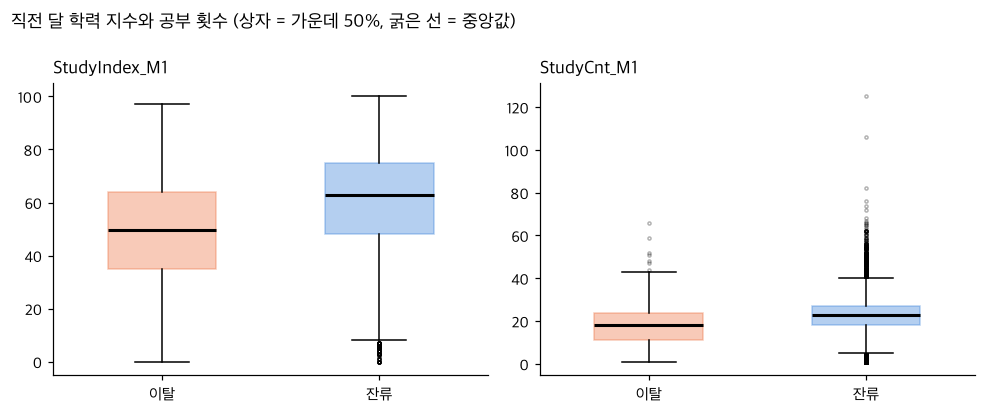

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, c in zip(axes, ["StudyIndex_M1", "StudyCnt_M1"]):
    data = [df.loc[df.churn == 1, c].dropna(), df.loc[df.churn == 0, c].dropna()]
    bp = ax.boxplot(data, tick_labels=["이탈", "잔류"], widths=0.5, patch_artist=True,
                    medianprops=dict(color="black", linewidth=2),
                    flierprops=dict(markersize=2, alpha=0.3))
    for patch, color in zip(bp["boxes"], [CHURN, STAY]):
        patch.set(facecolor=color, alpha=0.35, edgecolor=color)
    ax.set_title(c, loc="left")
fig.suptitle("직전 달 학력 지수와 공부 횟수 (상자 = 가운데 50%, 굵은 선 = 중앙값)", x=0.01, ha="left")
plt.tight_layout()
plt.show()

항목 하나만으로 AUC 를 재면 각 항목이 얼마나 쓸모 있는지 비교할 수 있습니다.
방향(높을수록/낮을수록 이탈)은 AUC 가 0.5 보다 큰 쪽으로 맞춥니다.

In [9]:
def single_auc(col):
    ok = df[col].notna()
    a = roc_auc_score(df.churn[ok], df[col][ok])
    return max(a, 1 - a), ("높을수록" if a > 0.5 else "낮을수록") + " 이탈"

features = [c for c in ORIGINAL_COLS if c not in ("ID", "survived")]
auc_table = (pd.DataFrame([(c, *single_auc(c)) for c in features], columns=["항목", "AUC", "방향"])
             .sort_values("AUC", ascending=False, ignore_index=True))
auc_table

,항목,AUC,방향
0,StudyIndex_M1,0.661,낮을수록 이탈
1,StudyCnt_M1,0.648,낮을수록 이탈
2,StudyIndex_M2,0.596,낮을수록 이탈
3,AGE,0.594,높을수록 이탈
4,StudyCntCnt_M2,0.578,낮을수록 이탈
5,StudyIndex_M3,0.578,낮을수록 이탈
6,StudyCntCnt_M3,0.553,낮을수록 이탈
7,Exam3_M1,0.540,낮을수록 이탈
8,Exam1_M1,0.536,낮을수록 이탈
9,Exam2_M1,0.531,낮을수록 이탈


직전 달 학력 지수(0.661)와 공부 횟수(0.648)가 가장 강하고, 시험 점수는 모두 0.54 이하로 약합니다.

## 4. 시험 점수와 그 변화

처음 가설은 "공부 경험이 나쁘면 그만둔다 → 시험 성적이 떨어지는 사람이 그만둘 것"이었습니다.
세 시험의 합(총점)과 달 사이의 변화량을 비교합니다. 총점은 세 시험을 모두 본 달만 계산합니다.

**Mann-Whitney U 검정**의 p값은 "실제로는 차이가 없는데 우연히 이만큼 차이가 날 확률"입니다. 0.05 보다 작으면 우연으로 보기 어렵다고 판단합니다.

In [10]:
exams = ["Exam1", "Exam2", "Exam3"]
for m in ["M3", "M2", "M1"]:
    df[f"Total_{m}"] = df[[f"{e}_{m}" for e in exams]].sum(axis=1, min_count=3)
df["Total_diff_M3M2"] = df["Total_M2"] - df["Total_M3"]
df["Total_diff_M2M1"] = df["Total_M1"] - df["Total_M2"]

rows = []
for c in ["Total_M3", "Total_M2", "Total_M1", "Total_diff_M3M2", "Total_diff_M2M1"]:
    a, b = df.loc[df.churn == 1, c].dropna(), df.loc[df.churn == 0, c].dropna()
    rows.append({"항목": c, "이탈 중앙값": a.median(), "잔류 중앙값": b.median(),
                 "p값": mannwhitneyu(a, b).pvalue})
pd.DataFrame(rows).style.format({"이탈 중앙값": "{:.2f}", "잔류 중앙값": "{:.2f}", "p값": "{:.3f}"})

,항목,이탈 중앙값,잔류 중앙값,p값
0,Total_M3,300.10,302.86,0.130
1,Total_M2,299.28,301.56,0.120
2,Total_M1,293.15,299.18,0.004
3,Total_diff_M3M2,-2.15,-1.64,0.530
4,Total_diff_M2M1,-2.41,-1.83,0.127


- 이탈 회원의 총점은 300 → 299 → 293 으로 내려가고, 직전 달 차이(6점)는 유의합니다(p = 0.004).
- 그러나 달 사이 변화량은 이탈·잔류 모두 비슷하게 조금씩 떨어지고, 차이는 우연으로 설명됩니다.
- 성적 추이 가설은 약하게만 맞습니다. 학습 지표의 직전 달 하락이 훨씬 강한 신호입니다.

## 5. 시험을 안 보는 것이 신호다

점수 대신 **시험을 봤는지**(칸이 비어 있지 않은지)를 봅니다.

먼저 주의할 점이 있습니다. 가입한 지 1–2개월 된 회원은 두세 달 전 기록이 아예 없어 '시험을 안 본 것'으로 잡히는데,
이 회원들은 그만두는 비율도 낮습니다. 그래서 **3개월 기록이 모두 있는 회원**만으로 비교합니다.

In [11]:
full = df[df["StudyCntCnt_M3"].notna()]       # 세 달 전 학습 기록까지 있는 회원
print(f"3개월 기록 회원 {len(full):,}명, 이탈률 {full.churn.mean():.2%}")

rows = []
for e in exams:
    for m in ["M1", "M2", "M3"]:
        missed = full[f"{e}_{m}"].isna()
        a, b = full.churn[missed], full.churn[~missed]
        table = [[a.sum(), len(a) - a.sum()], [b.sum(), len(b) - b.sum()]]
        rows.append({"시험": e, "달": m, "안 본 회원 이탈률": a.mean(), "본 회원 이탈률": b.mean(),
                     "몇 배": a.mean() / b.mean(), "p값": fisher_exact(table).pvalue})
missing_test = pd.DataFrame(rows)
missing_test.style.format({"안 본 회원 이탈률": "{:.2%}", "본 회원 이탈률": "{:.2%}",
                           "몇 배": "{:.2f}", "p값": "{:.1e}"})

3개월 기록 회원 26,123명, 이탈률 2.97%


,시험,달,안 본 회원 이탈률,본 회원 이탈률,몇 배,p값
0,Exam1,M1,2.89%,2.98%,0.97,8.3e-01
1,Exam1,M2,2.96%,2.97%,1.00,1.0e+00
2,Exam1,M3,2.90%,2.98%,0.97,8.4e-01
3,Exam2,M1,5.97%,2.61%,2.29,1.0e-18
4,Exam2,M2,5.41%,2.69%,2.01,6.7e-13
5,Exam2,M3,4.51%,2.81%,1.61,9.5e-06
6,Exam3,M1,5.31%,2.41%,2.21,4.6e-24
7,Exam3,M2,4.81%,2.56%,1.88,7.1e-15
8,Exam3,M3,4.49%,2.65%,1.69,4.5e-10


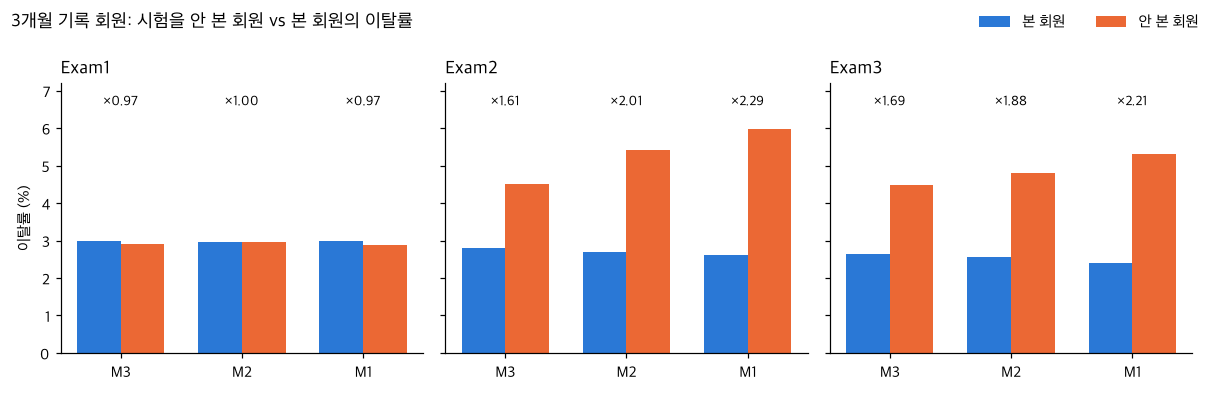

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True)
for ax, e in zip(axes, exams):
    t = missing_test[missing_test["시험"] == e].set_index("달").loc[["M3", "M2", "M1"]]
    x = np.arange(3)
    ax.bar(x - 0.18, t["본 회원 이탈률"] * 100, width=0.36, color=STAY, label="본 회원")
    ax.bar(x + 0.18, t["안 본 회원 이탈률"] * 100, width=0.36, color=CHURN, label="안 본 회원")
    for xi, r in zip(x, t["몇 배"]):
        ax.text(xi, 6.6, f"×{r:.2f}", ha="center", fontsize=9)
    ax.set_xticks(x, t.index)
    ax.set_title(e, loc="left")
axes[0].set_ylabel("이탈률 (%)")
axes[0].set_ylim(0, 7.2)
fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, loc="upper right", ncol=2)
fig.suptitle("3개월 기록 회원: 시험을 안 본 회원 vs 본 회원의 이탈률", x=0.01, ha="left")
plt.tight_layout()
plt.show()

- **시험 2·3 을 안 본 회원은 모든 달에서 1.6–2.3배 더 그만두고**, 직전 달일수록 차이가 큽니다.
- **시험 1 은 안 봐도 차이가 없습니다.**

## 6. 모델 학습과 평가

**모델**은 회원 기록을 넣으면 위험 점수를 내놓는 계산 규칙이고, 정답이 붙은 과거 기록에서 학습합니다.
다섯 단계로 넣는 정보와 규칙의 형태를 바꿔 가며 성능을 비교합니다.

| 단계 | 넣은 정보 | 모델 | 학습 목표 |
|---|---|---|---|
| 1 | 시험 9개(3종 × 3달)를 봤는지 여부 | 항목 쌍의 조합까지 보는 단순한 식 | 부드러운 AUC |
| 2 | + 이용 기간 | 같음 | 부드러운 AUC |
| 3 | 나이를 뺀 모든 기록 + 각 항목이 비었는지 | 신경망 하나 | 부드러운 AUC |
| 4 | 같음 | 신경망 5개의 평균 | 부드러운 AUC |
| 5 | 같음 | 신경망 + 직선식 + 결정나무 모음의 앙상블 | 각자 |

### 평가 방법: 교차검증

회원을 다섯 묶음으로 나눠 네 묶음으로 학습하고, 학습에 쓰지 않은 나머지 한 묶음으로 채점합니다.
묶음을 바꿔 가며 5번, 나누는 방식을 바꿔 `N_REPEATS` 번 반복합니다.
묶음마다 이탈 비율이 같도록 나눕니다(층화 분할). 모든 모델이 같은 묶음을 쓰므로 묶음끼리 짝지어 비교할 수 있습니다.

### 6.1 학습에 쓸 입력 만들기

In [13]:
y = df["churn"].to_numpy()

# 단계 1·2: 시험 9개 응시 여부 → 9비트 패턴 번호 (0–511)
EXAM_COLS = [f"{e}_{m}" for e in exams for m in ["M1", "M2", "M3"]]
took = df[EXAM_COLS].notna().to_numpy(dtype=np.int64)
pattern = took @ (1 << np.arange(len(EXAM_COLS)))
month = df["Month"].to_numpy()

# 단계 3–5: 나이를 뺀 원래 항목 16개
RAW_COLS = [c for c in ORIGINAL_COLS if c not in ("ID", "survived", "AGE")]
raw = df[RAW_COLS]
MISS_COLS = [c for c in RAW_COLS if raw[c].isna().any()]   # 빈칸이 있는 항목 → '비었는지' 열을 하나씩 붙인다
print(f"응시 패턴 {len(np.unique(pattern))}종 / 원래 항목 {len(RAW_COLS)}개 + 빈칸 표시 {len(MISS_COLS)}개")

응시 패턴 195종 / 원래 항목 16개 + 빈칸 표시 15개


### 6.2 단계 1·2 — 응시 여부(+ 이용 기간) 모델

입력이 "봤다/안 봤다" 9개와 이용 기간(1–39개월)뿐이라, 서로 다른 입력 조합(칸)이 많지 않습니다.
그래서 회원 쌍 1,700만 개를 하나하나 비교하는 대신 **칸마다 이탈·잔류 인원을 세어** 부드러운 AUC 를 정확히 계산합니다.

모델은 각 항목의 가중치에 더해 **항목 두 개씩의 조합**(예: "시험 2와 시험 3을 둘 다 안 봤다")에도 가중치를 둡니다.
이용 기간은 `기간/39` 와 `log(기간)/log(39)` 두 열로 넣어, 가입 초기에 이탈률이 낮은 굽은 모양을 담을 수 있게 합니다.

In [14]:
def make_cells(use_month):
    """서로 다른 입력 조합(칸)과 그 입력값, 회원 → 칸 번호."""
    m = month if use_month else np.zeros_like(month)
    keys, row_cell = np.unique(np.stack([pattern, m], 1), axis=0, return_inverse=True)
    x = ((keys[:, :1] >> np.arange(len(EXAM_COLS))) & 1).astype(np.float32)
    if use_month:
        mm = keys[:, 1]
        x = np.hstack([x, np.stack([mm / 39, np.log(mm) / np.log(39)], 1)]).astype(np.float32)
    return torch.tensor(x), row_cell.ravel()


class Interaction(torch.nn.Module):
    """점수 = Σ w_k x_k + Σ_{k<l} v_kl x_k x_l + b"""
    def __init__(self, d):
        super().__init__()
        self.pairs = list(itertools.combinations(range(d), 2))
        self.f = torch.nn.Linear(d + len(self.pairs), 1)

    def forward(self, x):
        cross = torch.stack([x[:, k] * x[:, l] for k, l in self.pairs], dim=1)
        return self.f(torch.cat([x, cross], dim=1)).squeeze(-1)


def soft_auc_cells(scores, n_pos, n_neg, tau=1.0):
    """칸 i 의 이탈 n_pos[i]명 × 칸 j 의 잔류 n_neg[j]명은 모두 같은 점수 차 s_i − s_j 를 갖는다."""
    p = n_pos > 0
    w = n_pos[p][:, None] * n_neg[None, :]
    return (w * torch.sigmoid((scores[p][:, None] - scores[None, :]) / tau)).sum() / w.sum()


def fit_cells(x_cell, row_cell, train_idx, seed, steps=500, lr=0.05, l2=1e-4):
    n = len(x_cell)
    n_pos = torch.tensor(np.bincount(row_cell[train_idx][y[train_idx] == 1], minlength=n), dtype=torch.float32)
    n_neg = torch.tensor(np.bincount(row_cell[train_idx][y[train_idx] == 0], minlength=n), dtype=torch.float32)
    torch.manual_seed(seed)
    model = Interaction(x_cell.shape[1])
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(steps):
        opt.zero_grad()
        penalty = sum((p ** 2).sum() for p in model.parameters())
        loss = 1 - soft_auc_cells(model(x_cell), n_pos, n_neg) + l2 * penalty
        loss.backward()
        opt.step()
    with torch.no_grad():
        return model(x_cell).numpy()[row_cell]      # 칸 점수 → 회원 점수


CELLS = {"exam": make_cells(False), "exam+month": make_cells(True)}
print({k: len(v[0]) for k, v in CELLS.items()}, "칸")

{'exam': 195, 'exam+month': 1865} 칸


### 6.3 단계 3·4 — 전체 기록 신경망

- **빈칸 처리**: 각 항목을 학습 묶음의 평균 0·표준편차 1 로 맞춘 뒤 빈칸은 0(= 평균)으로 채웁니다.
  대신 "이 항목이 비어 있었다"는 0/1 열을 따로 붙여, 시험을 안 본 정보도 잃지 않게 합니다.
  (원래 점수 0 으로 채우지 않는 이유: 시험 1 에는 실제 0점이 있어 빈칸과 섞입니다.)
- **신경망**: 입력 31개 → 64 → 64 → 1. 학습 묶음의 모든 (이탈, 잔류) 쌍으로 부드러운 AUC 를 계산합니다.
- **언제 멈출지**: 학습 묶음에서 10% 를 떼어 두고, 그 10% 의 AUC 가 가장 높았던 시점의 신경망을 씁니다.
  너무 오래 학습하면 학습 데이터를 외워 처음 보는 회원에게 오히려 나빠지기 때문입니다.
- **단계 4**: 초기값만 다르게 신경망 5개를 학습해 점수 순위를 평균합니다.

In [15]:
def encode(train_idx):
    """학습 묶음 기준 표준화 → 빈칸 0, 빈칸 표시 열을 붙인다."""
    mu, sd = raw.iloc[train_idx].mean(), raw.iloc[train_idx].std().replace(0, 1)
    z = ((raw - mu) / sd).fillna(0.0)
    missing = raw[MISS_COLS].isna().astype(float).add_prefix("miss_")
    return pd.concat([z, missing], axis=1).to_numpy(dtype=np.float32)


class MLP(torch.nn.Module):
    def __init__(self, d, hidden=64):
        super().__init__()
        self.f = torch.nn.Sequential(
            torch.nn.Linear(d, hidden), torch.nn.ReLU(),
            torch.nn.Linear(hidden, hidden), torch.nn.ReLU(),
            torch.nn.Linear(hidden, 1),
        )

    def forward(self, x):
        return self.f(x).squeeze(-1)


def fit_mlp(x, y_tr, seed, max_steps=600, eval_every=10, patience=10, lr=3e-3, tau=1.0):
    tr, inner = train_test_split(np.arange(len(y_tr)), test_size=0.1, stratify=y_tr, random_state=seed)
    xt, xi = torch.tensor(x[tr]), torch.tensor(x[inner])
    is_pos, is_neg = torch.tensor(y_tr[tr] == 1), torch.tensor(y_tr[tr] == 0)

    torch.manual_seed(seed)
    model = MLP(x.shape[1])
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    best, best_state, bad = -1.0, None, 0
    for step in range(1, max_steps + 1):
        model.train()
        opt.zero_grad()
        s = model(xt)
        soft = torch.sigmoid((s[is_pos][:, None] - s[is_neg][None, :]) / tau).mean()
        (1 - soft).backward()
        opt.step()
        if step % eval_every == 0:
            model.eval()
            with torch.no_grad():
                auc = roc_auc_score(y_tr[inner], model(xi).numpy())
            if auc > best:
                best, bad = auc, 0
                best_state = {k: v.clone() for k, v in model.state_dict().items()}
            else:
                bad += 1
                if bad >= patience:
                    break
    model.load_state_dict(best_state)
    model.eval()
    return model


def predict(model, x):
    with torch.no_grad():
        return model(torch.tensor(x)).numpy()

### 6.4 단계 5 — 앙상블

같은 입력으로 성격이 다른 모델 두 개를 더 학습해, 신경망(5개 평균)과 의견을 합칩니다.

- **직선식(로지스틱 회귀)**: 각 항목에 가중치를 곱해 더하는 단순한 규칙.
- **결정나무 모음(HistGradientBoosting)**: "학력 지수가 50보다 낮은가?" 같은 질문을 이어 가며 나누는 나무를 여러 그루 쌓은 모델.
  빈칸을 스스로 처리하므로 원래 값을 그대로 넣습니다.

두 모델 모두 이탈 회원이 적은 것을 보정하도록 `class_weight="balanced"` 를 씁니다.
합칠 때는 묶음 안에서 각 모델의 점수를 **순위**로 바꿔 평균합니다. AUC 는 순위만 보므로, 척도가 다른 점수를 섞을 때 안전합니다.
응시 여부 모델(단계 2)도 넣어 보고, 네 모델의 가능한 조합 15가지를 모두 채점합니다.

In [16]:
def fit_logreg(x, train_idx):
    return LogisticRegression(max_iter=2000, class_weight="balanced").fit(x[train_idx], y[train_idx])


def fit_hgb(train_idx, seed):
    return HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=500, early_stopping=True, validation_fraction=0.1,
        n_iter_no_change=30, class_weight="balanced", random_state=seed,
    ).fit(raw.iloc[train_idx], y[train_idx])


def to_rank(score):
    return rankdata(score) / len(score)        # 0–1 사이 순위

### 6.5 교차검증 실행

묶음마다 위의 모델을 모두 학습하고 채점합니다. 진행 상황이 묶음마다 한 줄씩 출력됩니다.

In [17]:
ENSEMBLE_MEMBERS = ["mlp_x5", "logreg", "hgb", "exam+month"]
stage_rows, combo_rows = [], []
t_start = time.time()

for rep in range(N_REPEATS):
    folds = StratifiedKFold(N_SPLITS, shuffle=True, random_state=rep)
    for fold, (tr, va) in enumerate(folds.split(raw, y)):
        t0 = time.time()
        seed = rep * N_SPLITS + fold
        pred = {}

        # 단계 1·2
        for name, (x_cell, row_cell) in CELLS.items():
            pred[name] = fit_cells(x_cell, row_cell, tr, seed)[va]

        # 단계 3·4
        x = encode(tr)
        pred["mlp_x1"] = predict(fit_mlp(x[tr], y[tr], seed), x[va])
        pred["mlp_x5"] = np.mean([to_rank(predict(fit_mlp(x[tr], y[tr], seed * 100 + k), x[va]))
                                  for k in range(5)], axis=0)

        # 단계 5 구성원
        pred["logreg"] = fit_logreg(x, tr).decision_function(x[va])
        pred["hgb"] = fit_hgb(tr, seed).predict_proba(raw.iloc[va])[:, 1]

        for name, p in pred.items():
            stage_rows.append({"model": name, "repeat": rep, "fold": fold, "auc": roc_auc_score(y[va], p)})
        ranks = {m: to_rank(pred[m]) for m in ENSEMBLE_MEMBERS}
        for r in range(1, len(ENSEMBLE_MEMBERS) + 1):
            for combo in itertools.combinations(ENSEMBLE_MEMBERS, r):
                combo_rows.append({"combo": " + ".join(combo), "repeat": rep, "fold": fold,
                                   "auc": roc_auc_score(y[va], np.mean([ranks[m] for m in combo], axis=0))})

        done = {r["model"]: r["auc"] for r in stage_rows[-len(pred):]}
        print(f"반복 {rep} 묶음 {fold} ({time.time() - t0:4.1f}초) "
              + "  ".join(f"{k} {v:.3f}" for k, v in done.items()), flush=True)

stages = pd.DataFrame(stage_rows)
combos = pd.DataFrame(combo_rows)
print(f"\n총 {(time.time() - t_start) / 60:.1f}분")

반복 0 묶음 0 (14.8초) exam 0.610  exam+month 0.636  mlp_x1 0.663  mlp_x5 0.690  logreg 0.693  hgb 0.693


반복 0 묶음 1 (16.6초) exam 0.603  exam+month 0.627  mlp_x1 0.694  mlp_x5 0.706  logreg 0.691  hgb 0.690


반복 0 묶음 2 (18.5초) exam 0.625  exam+month 0.614  mlp_x1 0.663  mlp_x5 0.670  logreg 0.661  hgb 0.661


반복 0 묶음 3 (20.6초) exam 0.619  exam+month 0.615  mlp_x1 0.622  mlp_x5 0.633  logreg 0.643  hgb 0.639


반복 0 묶음 4 (25.1초) exam 0.592  exam+month 0.595  mlp_x1 0.662  mlp_x5 0.668  logreg 0.676  hgb 0.681


반복 1 묶음 0 (23.1초) exam 0.622  exam+month 0.629  mlp_x1 0.682  mlp_x5 0.686  logreg 0.676  hgb 0.683


... (16 outputs left out)

반복 4 묶음 2 (21.6초) exam 0.567  exam+month 0.609  mlp_x1 0.667  mlp_x5 0.687  logreg 0.682  hgb 0.671


반복 4 묶음 3 (22.6초) exam 0.595  exam+month 0.618  mlp_x1 0.668  mlp_x5 0.676  logreg 0.672  hgb 0.672


반복 4 묶음 4 (23.2초) exam 0.602  exam+month 0.618  mlp_x1 0.690  mlp_x5 0.673  logreg 0.653  hgb 0.682



총 9.0분


### 6.6 결과

점수는 "반복마다 5묶음 평균"을 낸 뒤 그 평균입니다. 표준편차는 반복 사이의 흔들림입니다(`QUICK = True` 면 반복이 1번이라 비어 있습니다).

In [18]:
def summarize(table, key):
    per_repeat = table.groupby([key, "repeat"])["auc"].mean()
    return per_repeat.groupby(key).agg(["mean", "std"])

STAGES = {
    "1 · 시험 응시 여부만": "exam",
    "2 · + 이용 기간": "exam+month",
    "3 · 전체 기록, 신경망 하나": "mlp_x1",
    "4 · 신경망 5개 평균": "mlp_x5",
}
stage_summary = summarize(stages, "model")
combo_summary = summarize(combos, "combo").sort_values("mean", ascending=False)
best_combo = combo_summary.index[0]

result = pd.concat([
    stage_summary.loc[list(STAGES.values())].set_axis(list(STAGES.keys())),
    combo_summary.loc[[best_combo]].set_axis([f"5 · 앙상블 ({best_combo})"]),
]).rename(columns={"mean": "AUC 평균", "std": "반복 간 표준편차"})
result

,AUC 평균,반복 간 표준편차
1 · 시험 응시 여부만,0.609,0.006
2 · + 이용 기간,0.621,0.005
"3 · 전체 기록, 신경망 하나",0.673,0.008
4 · 신경망 5개 평균,0.680,0.005
5 · 앙상블 (mlp_x5 + logreg + hgb),0.687,0.004


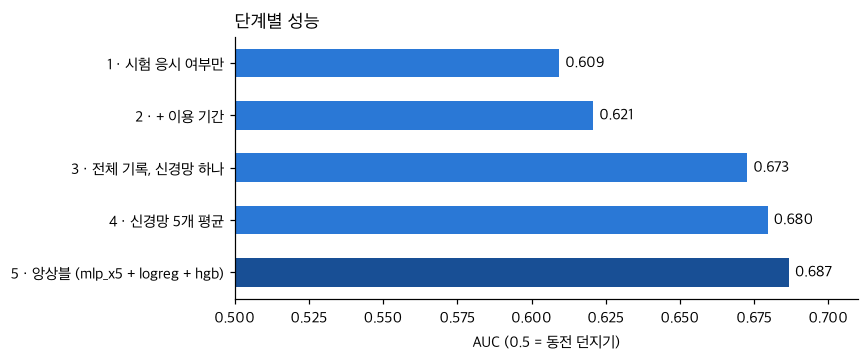

In [19]:
fig, ax = plt.subplots(figsize=(8, 3.4))
names, vals = result.index[::-1], result["AUC 평균"][::-1]
ax.barh(names, vals - 0.5, left=0.5, color=["#184f95"] + [STAY] * (len(vals) - 1), height=0.55)
for i, v in enumerate(vals):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center")
ax.axvline(0.5, color="gray", ls="--", lw=1)
ax.set_xlim(0.5, 0.71)
ax.set_xlabel("AUC (0.5 = 동전 던지기)")
ax.set_title("단계별 성능", loc="left")
plt.tight_layout()
plt.show()

#### 앙상블 조합 15가지

네 구성원(신경망 5개 평균, 직선식, 결정나무 모음, 응시 여부 + 이용 기간)의 모든 조합입니다.
"우위 묶음"은 같은 묶음에서 가장 좋은 단일 모델보다 점수가 높았던 횟수입니다.
점수가 채점마다 0.015 정도 흔들리므로, 차이가 작을 때는 이 횟수가 더 믿을 만한 판단 근거입니다.

In [20]:
wide = combos.pivot_table(index=["repeat", "fold"], columns="combo", values="auc")
best_single = combo_summary.loc[ENSEMBLE_MEMBERS, "mean"].idxmax()
combo_table = combo_summary.assign(
    단일최고대비=[(wide[c] - wide[best_single]).mean() for c in combo_summary.index],
    우위묶음=[f"{(wide[c] > wide[best_single]).sum()}/{len(wide)}" for c in combo_summary.index],
).rename(columns={"mean": "AUC 평균", "std": "반복 간 표준편차"}).round(4)
print(f"단일 최고: {best_single}")
combo_table

단일 최고: mlp_x5


,AUC 평균,반복 간 표준편차,단일최고대비,우위묶음
combo,,,,
mlp_x5 + logreg + hgb,0.687,0.004,0.007,22/25
mlp_x5 + hgb,0.686,0.004,0.007,22/25
logreg + hgb,0.686,0.004,0.006,17/25
mlp_x5 + logreg + hgb + exam+month,0.684,0.004,0.005,18/25
mlp_x5 + logreg,0.681,0.004,0.002,15/25
mlp_x5 + hgb + exam+month,0.681,0.004,0.002,13/25
logreg + hgb + exam+month,0.681,0.004,0.001,12/25
mlp_x5,0.680,0.005,0.000,0/25
hgb,0.678,0.007,-0.002,12/25


보고서 작성 시(`QUICK = False`) 결과는 다음과 같았습니다. 실행 환경의 스레드 수 등에 따라 셋째 자리가 조금 다를 수 있습니다.

| 단계 | AUC |
|---|---:|
| 1 · 시험 응시 여부만 | 0.609 |
| 2 · + 이용 기간 | 0.621 |
| 3 · 전체 기록, 신경망 하나 | 0.673 |
| 4 · 신경망 5개 평균 | 0.680 |
| 5 · 앙상블 (신경망 + 직선식 + 결정나무 모음) | 0.687 |

- 시험 응시 여부만으로 0.61, 이용 기간을 더해 0.62. 이용 기간 덕분에 모델이 '기록이 없는 신규 회원'과 '시험을 건너뛴 회원'을 구분합니다.
- 학습 지표까지 넣자 0.67 로 크게 오릅니다. 오른 몫 대부분은 직전 달 학력 지수 하나(혼자서 0.661)로 설명됩니다.
- 신경망이 직선식보다 낫지는 않았습니다. 이탈 868명으로는 복잡한 규칙을 뒷받침하기 어렵습니다.
- 성격이 다른 모델, 특히 결정나무 모음을 섞을 때 앙상블 효과가 납니다. 응시 여부 모델은 같은 정보를 이미 빈칸 표시로 갖고 있어 섞으면 오히려 떨어집니다.

## 7. 정리

- 회원 기록만으로 그만둘 사람을 동전 던지기보다 확실히 낫게, 그러나 확신할 정도는 아니게 가려낼 수 있습니다 (AUC 약 0.69).
- 쓸 만한 신호는 두 가지입니다.
  1. **직전 달에 공부 횟수와 학력 지수가 떨어진 회원**
  2. **시험 2·3 을 건너뛰기 시작한 회원**, 특히 직전 달에
- 조심할 점: 이탈 868명이라 모델 간 차이(0.01 이하)는 채점마다 흔들리는 폭(약 0.015)보다 작습니다.
  최종 조합은 15가지 중 가장 좋은 것을 같은 채점으로 골랐으므로 새 회원에게는 조금 낮게 나올 수 있습니다.
- 다음에 해 볼 것: 나이 넣기(혼자서 0.594), 직전 달 하락폭 피처, 시험 2·3 미응시 횟수, 결정나무 모음 조정.